In [1]:
from google.colab import files

uploaded = files.upload()

Saving Employee_Attrition_Round2_Raw.zip to Employee_Attrition_Round2_Raw.zip


In [2]:
import zipfile
from pathlib import Path

zip_path = "/content/Employee_Attrition_Round2_Raw.zip"
extract_dir = "/content/Employee_Attrition_Round2_Raw"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("ZIP extracted successfully!")

# Find and display all CSV files
for file in Path(extract_dir).rglob("*.csv"):
    print(file)

ZIP extracted successfully!
/content/Employee_Attrition_Round2_Raw/data/raw/movement.csv
/content/Employee_Attrition_Round2_Raw/data/raw/employees.csv
/content/Employee_Attrition_Round2_Raw/data/raw/compensation.csv
/content/Employee_Attrition_Round2_Raw/data/raw/engagement.csv
/content/Employee_Attrition_Round2_Raw/data/raw/attendance.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from pathlib import Path

DATA_DIR = Path("/content/Employee_Attrition_Round2_Raw/data/raw")

employees = pd.read_csv(DATA_DIR / "employees.csv")
attendance = pd.read_csv(DATA_DIR / "attendance.csv")
compensation = pd.read_csv(DATA_DIR / "compensation.csv")
engagement = pd.read_csv(DATA_DIR / "engagement.csv")
movement = pd.read_csv(DATA_DIR / "movement.csv")

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [5]:
datasets = {
    "Employees": employees,
    "Attendance": attendance,
    "Compensation": compensation,
    "Engagement": engagement,
    "Movement": movement
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Employees: 1008 rows, 8 columns
Attendance: 1006 rows, 6 columns
Compensation: 1005 rows, 6 columns
Engagement: 1007 rows, 5 columns
Movement: 1006 rows, 6 columns


In [6]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(f"DATASET: {name}")
    print("=" * 60)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())


DATASET: Employees

Column names:
['employee_id', 'department', 'role', 'tenure_years', 'grade', 'age', 'education_level', 'work_location']

First 5 rows:


,employee_id,department,role,tenure_years,grade,age,education_level,work_location
0,EMP0001,Operations,Operations Manager,1.5,G4,24,Bachelor,Coimbatore
1,EMP0002,HR,HR Executive,1.4,G4,24,Diploma,Chennai
2,EMP0003,Customer Support,Support Specialist,1.3,G5,23,Bachelor,Remote
3,EMP0004,Operations,Team Lead,2.3,G2,30,Master,Bengaluru
4,EMP0005,Engineering,Data Analyst,4.7,G2,25,Master,Bengaluru



DATASET: Attendance

Column names:
['employee_id', 'absence_days', 'overtime_hours', 'leave_days', 'late_arrivals', 'attendance_months']

First 5 rows:


,employee_id,absence_days,overtime_hours,leave_days,late_arrivals,attendance_months
0,EMP0001,3,11.2,7,2,12
1,EMP0002,1,23.8,5,2,12
2,EMP0003,1,7.1,4,0,12
3,EMP0004,3,3.4,5,1,12
4,EMP0005,8,22.5,6,4,12



DATASET: Compensation

Column names:
['employee_id', 'salary_band', 'monthly_salary', 'increment_pct', 'benefits_score', 'last_increment_years']

First 5 rows:


,employee_id,salary_band,monthly_salary,increment_pct,benefits_score,last_increment_years
0,EMP0001,Band C,56600,7.3,1.5,4.2
1,EMP0002,Band D,75600,4.7,3.0,0.8
2,EMP0003,Band D,97500,4.3,3.1,3.5
3,EMP0004,Band B,37000,5.9,3.1,1.5
4,EMP0005,Band B,36800,8.1,2.6,0.5



DATASET: Engagement

Column names:
['employee_id', 'satisfaction_score', 'work_life_balance_score', 'manager_support_score', 'survey_participation']

First 5 rows:


,employee_id,satisfaction_score,work_life_balance_score,manager_support_score,survey_participation
0,EMP0001,3.2,3.1,3.1,Yes
1,EMP0002,2.7,3.4,5.0,Yes
2,EMP0003,NaN,3.7,2.4,Yes
3,EMP0004,2.9,3.6,NaN,Yes
4,EMP0005,3.9,2.5,4.0,Yes



DATASET: Movement

Column names:
['employee_id', 'promotion_count', 'last_promotion_years', 'transfer_count', 'exit_status', 'exit_date']

First 5 rows:


,employee_id,promotion_count,last_promotion_years,transfer_count,exit_status,exit_date
0,EMP0001,1,0.3,0,Stayed,NaN
1,EMP0002,1,0.0,0,Stayed,NaN
2,EMP0003,1,0.8,0,Stayed,NaN
3,EMP0004,1,0.8,0,Stayed,NaN
4,EMP0005,0,NaN,0,Stayed,NaN


In [7]:
for name, df in datasets.items():
    print(f"\n{name}")
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if missing.empty:
        print("No missing values found.")
    else:
        print(missing)


Employees
No missing values found.

Attendance
No missing values found.

Compensation
No missing values found.

Engagement
satisfaction_score         35
work_life_balance_score    36
manager_support_score      35
dtype: int64

Movement
last_promotion_years    540
exit_date               945
dtype: int64


In [8]:
for name, df in datasets.items():
    duplicate_count = df["employee_id"].duplicated().sum()

    print(
        f"{name}: {duplicate_count} duplicate employee IDs"
    )

Employees: 8 duplicate employee IDs
Attendance: 6 duplicate employee IDs
Compensation: 5 duplicate employee IDs
Engagement: 7 duplicate employee IDs
Movement: 6 duplicate employee IDs


In [9]:
for name, df in datasets.items():
    print(f"\n{name}:")
    print("Total missing values:", df.isnull().sum().sum())
    print("Total duplicate IDs:", df["employee_id"].duplicated().sum())


Employees:
Total missing values: 0
Total duplicate IDs: 8

Attendance:
Total missing values: 0
Total duplicate IDs: 6

Compensation:
Total missing values: 0
Total duplicate IDs: 5

Engagement:
Total missing values: 106
Total duplicate IDs: 7

Movement:
Total missing values: 1485
Total duplicate IDs: 6


In [10]:
print("Unique role names before cleaning:\n")

for role in sorted(employees["role"].dropna().unique()):
    print(repr(role))

Unique role names before cleaning:

' Data Analyst '
' HR Manager '
' Operations Associate '
' Operations Manager '
' Support Team Lead '
' Team Lead '
'ACCOUNT MANAGER'
'Account Manager'
'Accountant'
'Data Analyst'
'FINANCIAL ANALYST'
'Finance Manager'
'Financial Analyst'
'HR Executive'
'HR Manager'
'OPERATIONS ASSOCIATE'
'OPERATIONS MANAGER'
'Operations Associate'
'Operations Manager'
'QA Engineer'
'Recruiter'
'SUPPORT ASSOCIATE'
'SUPPORT SPECIALIST'
'SUPPORT TEAM LEAD'
'Sales Exec.'
'Sales Executive'
'Sales Manager'
'Senior Software Engineer'
'Software Engineer'
'Support Associate'
'Support Specialist'
'Support Team Lead'
'TEAM LEAD'
'Team Lead'


In [11]:
print(attendance["overtime_hours"].describe())

display(
    attendance.loc[
        attendance["overtime_hours"] > 60,
        ["employee_id", "overtime_hours"]
    ]
)

count    1006.000000
mean       12.626143
std        10.705885
min         0.300000
25%         5.500000
50%        10.100000
75%        16.800000
max       120.000000
Name: overtime_hours, dtype: float64


,employee_id,overtime_hours
69,EMP0070,92.0
708,EMP0709,120.0
728,EMP0729,84.0
844,EMP0845,105.0
923,EMP0924,78.0


In [12]:
quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isnull().sum().sum()),
        "Duplicate Employee IDs": int(
            df["employee_id"].duplicated().sum()
        )
    })

quality_summary = pd.DataFrame(quality_summary)

display(quality_summary)

,Dataset,Rows,Columns,Missing Cells,Duplicate Employee IDs
0,Employees,1008,8,0,8
1,Attendance,1006,6,0,6
2,Compensation,1005,6,0,5
3,Engagement,1007,5,106,7
4,Movement,1006,6,1485,6


In [13]:
from pathlib import Path

REPORT_DIR = Path("/content/outputs")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_summary.to_csv(
    REPORT_DIR / "initial_data_quality_report.csv",
    index=False
)

print("Initial data-quality report saved successfully!")

Initial data-quality report saved successfully!


In [14]:
# Inspect all rows associated with duplicate employee IDs
duplicate_employees = employees[
    employees["employee_id"].duplicated(keep=False)
].sort_values("employee_id")

display(duplicate_employees)

# Check whether duplicate IDs have identical or conflicting records
print("Duplicate employee IDs:",
      employees["employee_id"].duplicated().sum())

print("Fully identical duplicate rows:",
      employees.duplicated().sum())

print("Missing employee IDs:",
      employees["employee_id"].isna().sum())

,employee_id,department,role,tenure_years,grade,age,education_level,work_location
411,EMP0412,Operations,Operations Associate,7.4,G1,34,Doctorate,Chennai
1004,EMP0412,Operations,Operations Associate,7.4,G1,34,Doctorate,Chennai
513,EMP0514,Sales,Sales Manager,5.0,G2,32,Master,Chennai
1007,EMP0514,Sales,Sales Manager,5.0,G2,32,Master,Chennai
521,EMP0522,Sales,Sales Executive,6.5,G4,27,Bachelor,Hyderabad
1000,EMP0522,Sales,Sales Executive,6.5,G4,27,Bachelor,Hyderabad
626,EMP0627,Operations,Operations Manager,10.9,G2,36,Bachelor,Bengaluru
1006,EMP0627,Operations,Operations Manager,10.9,G2,36,Bachelor,Bengaluru
660,EMP0661,Sales,Account Manager,3.4,G1,29,Diploma,Chennai
1003,EMP0661,Sales,Account Manager,3.4,G1,29,Diploma,Chennai


Duplicate employee IDs: 8
Fully identical duplicate rows: 8
Missing employee IDs: 0


In [15]:
# Count rows that are fully identical
print("Fully identical duplicate rows:",
      employees.duplicated().sum())

# Check duplicate employee IDs with conflicting details
conflicts = employees.groupby("employee_id").nunique()
conflicting_ids = conflicts[(conflicts > 1).any(axis=1)]

print("Employee IDs with conflicting records:",
      len(conflicting_ids))

Fully identical duplicate rows: 8
Employee IDs with conflicting records: 0


In [16]:
from pathlib import Path
import pandas as pd

# Create the processed-data folder
PROCESSED_DIR = Path("/content/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Standardize text formatting
text_columns = [
    "department", "role", "grade",
    "education_level", "work_location"
]

for col in text_columns:
    employees[col] = employees[col].astype("string").str.strip()

employees["department"] = employees["department"].str.title()
employees["role"] = employees["role"].str.replace(
    r"\s+", " ", regex=True
)

# Remove exact duplicate records
employees = employees.drop_duplicates()

# Remove repeated employee IDs only after checking that
# duplicate IDs do not have conflicting employee details
conflicts = (
    employees.groupby("employee_id", dropna=False)
    .nunique()
    .gt(1)
    .any(axis=1)
)

conflicting_ids = conflicts[conflicts].index

if len(conflicting_ids) > 0:
    print("Conflicting employee IDs need investigation:")
    print(list(conflicting_ids))
else:
    employees = employees.drop_duplicates(
        subset="employee_id",
        keep="first"
    )

    employees.to_csv(
        PROCESSED_DIR / "employees_cleaned.csv",
        index=False
    )

    print("Employees dataset cleaned and saved.")
    print("Final shape:", employees.shape)
    print("Duplicate IDs remaining:",
          employees["employee_id"].duplicated().sum())
    print("Saved to:", PROCESSED_DIR / "employees_cleaned.csv")

Employees dataset cleaned and saved.
Final shape: (1000, 8)
Duplicate IDs remaining: 0
Saved to: /content/processed/employees_cleaned.csv


In [17]:
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_DIR = Path("/content/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Standardize employee IDs
attendance["employee_id"] = (
    attendance["employee_id"].astype("string").str.strip()
)

# Remove rows without a usable employee ID
attendance = attendance[
    attendance["employee_id"].notna()
    & attendance["employee_id"].ne("")
].copy()

# Remove fully identical rows
attendance = attendance.drop_duplicates()

# Check duplicate IDs for conflicting attendance records
conflicts = (
    attendance.groupby("employee_id")[
        ["absence_days", "overtime_hours", "leave_days",
         "late_arrivals", "attendance_months"]
    ]
    .nunique()
    .gt(1)
    .any(axis=1)
)

conflicting_ids = conflicts[conflicts].index

if len(conflicting_ids) > 0:
    print("Conflicting attendance records require review:")
    print(list(conflicting_ids))
else:
    attendance = attendance.drop_duplicates(
        subset="employee_id",
        keep="first"
    )

    # Flag unusual overtime; preserve values for investigation
    attendance["overtime_outlier_flag"] = (
        attendance["overtime_hours"] > 60
    ).astype(int)

    # Save cleaned dataset
    attendance.to_csv(
        PROCESSED_DIR / "attendance_cleaned.csv",
        index=False
    )

    print("Attendance dataset cleaned and saved.")
    print("Final shape:", attendance.shape)
    print("Duplicate IDs remaining:",
          attendance["employee_id"].duplicated().sum())
    print("Overtime outliers flagged:",
          attendance["overtime_outlier_flag"].sum())
    print("Saved to:", PROCESSED_DIR / "attendance_cleaned.csv")

Attendance dataset cleaned and saved.
Final shape: (1000, 7)
Duplicate IDs remaining: 0
Overtime outliers flagged: 5
Saved to: /content/processed/attendance_cleaned.csv


In [18]:
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_DIR = Path("/content/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Standardize employee IDs
compensation["employee_id"] = (
    compensation["employee_id"]
    .astype("string")
    .str.strip()
)

# Remove rows with missing or blank employee IDs
compensation = compensation[
    compensation["employee_id"].notna()
    & compensation["employee_id"].ne("")
].copy()

# Remove fully identical rows
compensation = compensation.drop_duplicates()

# Convert numeric columns safely
numeric_cols = [
    "monthly_salary",
    "increment_pct",
    "benefits_score",
    "last_increment_years"
]

for col in numeric_cols:
    compensation[col] = pd.to_numeric(
        compensation[col], errors="coerce"
    )

# Flag invalid compensation values for review
compensation["compensation_issue_flag"] = (
    (compensation["monthly_salary"] <= 0)
    | (compensation["increment_pct"] < 0)
    | (compensation["benefits_score"] < 1)
    | (compensation["benefits_score"] > 5)
    | (compensation["last_increment_years"] < 0)
).fillna(False).astype(int)

# Check whether duplicate IDs have conflicting values
check_cols = [
    "salary_band", "monthly_salary", "increment_pct",
    "benefits_score", "last_increment_years"
]

conflicts = (
    compensation.groupby("employee_id")[check_cols]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

conflicting_ids = conflicts[conflicts].index

if len(conflicting_ids) > 0:
    print("Conflicting compensation records need review:")
    print(list(conflicting_ids))
else:
    compensation = compensation.drop_duplicates(
        subset="employee_id", keep="first"
    )

    compensation.to_csv(
        PROCESSED_DIR / "compensation_cleaned.csv",
        index=False
    )

    print("Compensation dataset cleaned and saved.")
    print("Final shape:", compensation.shape)
    print("Duplicate IDs remaining:",
          compensation["employee_id"].duplicated().sum())
    print("Invalid compensation records flagged:",
          compensation["compensation_issue_flag"].sum())
    print("Saved to:", PROCESSED_DIR / "compensation_cleaned.csv")

Compensation dataset cleaned and saved.
Final shape: (1000, 7)
Duplicate IDs remaining: 0
Invalid compensation records flagged: 0
Saved to: /content/processed/compensation_cleaned.csv


In [19]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("/content/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Standardize employee IDs
engagement["employee_id"] = (
    engagement["employee_id"]
    .astype("string")
    .str.strip()
)

# Remove records without a usable employee ID
engagement = engagement[
    engagement["employee_id"].notna()
    & engagement["employee_id"].ne("")
].copy()

# Remove fully identical records
engagement = engagement.drop_duplicates()

# Convert survey scores to numeric
score_cols = [
    "satisfaction_score",
    "work_life_balance_score",
    "manager_support_score"
]

for col in score_cols:
    engagement[col] = pd.to_numeric(
        engagement[col], errors="coerce"
    )

# Flag missing scores before imputation
engagement["missing_survey_score_flag"] = (
    engagement[score_cols].isna().any(axis=1)
).astype(int)

# Check for invalid scores outside the expected 1–5 range
for col in score_cols:
    engagement.loc[
        ~engagement[col].between(1, 5) & engagement[col].notna(),
        col
    ] = pd.NA

# Fill missing survey scores with the column median
for col in score_cols:
    engagement[col] = engagement[col].fillna(
        engagement[col].median()
    )

# Check duplicate IDs for conflicting engagement records
check_cols = score_cols + ["survey_participation"]

conflicts = (
    engagement.groupby("employee_id")[check_cols]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

conflicting_ids = conflicts[conflicts].index

if len(conflicting_ids) > 0:
    print("Conflicting engagement records need review:")
    print(list(conflicting_ids))
else:
    engagement = engagement.drop_duplicates(
        subset="employee_id", keep="first"
    )

    engagement.to_csv(
        PROCESSED_DIR / "engagement_cleaned.csv",
        index=False
    )

    print("Engagement dataset cleaned and saved.")
    print("Final shape:", engagement.shape)
    print("Duplicate IDs remaining:",
          engagement["employee_id"].duplicated().sum())
    print("Rows with originally missing survey scores:",
          engagement["missing_survey_score_flag"].sum())
    print("Remaining missing survey scores:",
          engagement[score_cols].isna().sum().sum())
    print("Saved to:", PROCESSED_DIR / "engagement_cleaned.csv")

Engagement dataset cleaned and saved.
Final shape: (1000, 6)
Duplicate IDs remaining: 0
Rows with originally missing survey scores: 102
Remaining missing survey scores: 0
Saved to: /content/processed/engagement_cleaned.csv


In [20]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("/content/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Standardize employee IDs
movement["employee_id"] = (
    movement["employee_id"].astype("string").str.strip()
)

# Remove records without a usable employee ID
movement = movement[
    movement["employee_id"].notna()
    & movement["employee_id"].ne("")
].copy()

# Remove fully identical rows
movement = movement.drop_duplicates()

# Convert numeric columns
numeric_cols = ["promotion_count", "last_promotion_years", "transfer_count"]

for col in numeric_cols:
    movement[col] = pd.to_numeric(movement[col], errors="coerce")

# Normalize exit status
movement["exit_status"] = (
    movement["exit_status"].astype("string").str.strip().str.title()
)

# Parse exit date
movement["exit_date"] = pd.to_datetime(
    movement["exit_date"], errors="coerce"
)

# Preserve incomplete promotion history
movement["promotion_history_missing"] = (
    movement["last_promotion_years"].isna()
).astype(int)

# Flag invalid values for review
movement["movement_issue_flag"] = (
    (movement["promotion_count"] < 0)
    | (movement["last_promotion_years"] < 0)
    | (movement["transfer_count"] < 0)
    | ~movement["exit_status"].isin(["Left", "Stayed"])
).fillna(False).astype(int)

# Check duplicate IDs for conflicting records
check_cols = [
    "promotion_count", "last_promotion_years",
    "transfer_count", "exit_status", "exit_date"
]

conflicts = (
    movement.groupby("employee_id")[check_cols]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

conflicting_ids = conflicts[conflicts].index

if len(conflicting_ids) > 0:
    print("Conflicting movement records need review:")
    print(list(conflicting_ids))
else:
    movement = movement.drop_duplicates(
        subset="employee_id", keep="first"
    )

    movement.to_csv(
        PROCESSED_DIR / "movement_cleaned.csv",
        index=False
    )

    print("Movement dataset cleaned and saved.")
    print("Final shape:", movement.shape)
    print("Duplicate IDs remaining:",
          movement["employee_id"].duplicated().sum())
    print("Incomplete promotion histories:",
          movement["promotion_history_missing"].sum())
    print("Invalid records flagged:",
          movement["movement_issue_flag"].sum())
    print("Saved to:", PROCESSED_DIR / "movement_cleaned.csv")

Movement dataset cleaned and saved.
Final shape: (1000, 8)
Duplicate IDs remaining: 0
Incomplete promotion histories: 535
Invalid records flagged: 0
Saved to: /content/processed/movement_cleaned.csv


In [21]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("/content/processed")

# Load the cleaned CSV files
employees_cleaned = pd.read_csv(PROCESSED_DIR / "employees_cleaned.csv")
attendance_cleaned = pd.read_csv(PROCESSED_DIR / "attendance_cleaned.csv")
compensation_cleaned = pd.read_csv(PROCESSED_DIR / "compensation_cleaned.csv")
engagement_cleaned = pd.read_csv(PROCESSED_DIR / "engagement_cleaned.csv")
movement_cleaned = pd.read_csv(PROCESSED_DIR / "movement_cleaned.csv")

# Use employees as the main dataset and merge the other four
merged = employees_cleaned.copy()

for df in [
    attendance_cleaned,
    compensation_cleaned,
    engagement_cleaned,
    movement_cleaned
]:
    merged = merged.merge(
        df,
        on="employee_id",
        how="left",
        validate="one_to_one"
    )

# Validate the merged dataset
print("Merged dataset shape:", merged.shape)
print("Unique employee IDs:", merged["employee_id"].nunique())
print("Duplicate employee IDs:", merged["employee_id"].duplicated().sum())
print("\nMissing values by column:")
print(merged.isnull().sum()[merged.isnull().sum() > 0])

# Save the merged dataset
merged.to_csv(
    PROCESSED_DIR / "employee_attrition_merged.csv",
    index=False
)

print("\nMerged dataset saved successfully.")

Merged dataset shape: (1000, 32)
Unique employee IDs: 1000
Duplicate employee IDs: 0

Missing values by column:
last_promotion_years    535
exit_date               941
dtype: int64

Merged dataset saved successfully.


,department,total_employees,employees_left,attrition_rate_pct
1,Engineering,250,18,7.20
4,Operations,217,14,6.45
5,Sales,175,11,6.29
0,Customer Support,180,10,5.56
2,Finance,100,4,4.00
3,Hr,78,2,2.56


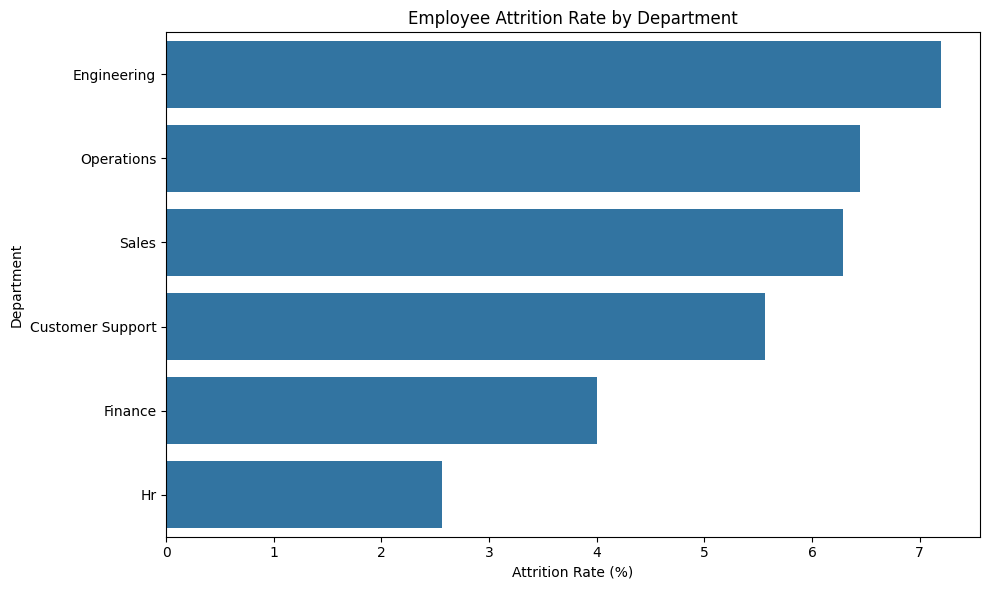

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate employee count and attrition rate by department
department_attrition = (
    merged.groupby("department")
    .agg(
        total_employees=("employee_id", "nunique"),
        employees_left=("exit_status", lambda x: (x == "Left").sum())
    )
    .reset_index()
)

department_attrition["attrition_rate_pct"] = (
    department_attrition["employees_left"]
    / department_attrition["total_employees"] * 100
).round(2)

department_attrition = department_attrition.sort_values(
    "attrition_rate_pct", ascending=False
)

display(department_attrition)

# Visualize attrition rate
plt.figure(figsize=(10, 6))
sns.barplot(
    data=department_attrition,
    x="attrition_rate_pct",
    y="department"
)
plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [23]:
print("Available columns in merged dataset:")
for col in merged.columns:
    print(col)

Available columns in merged dataset:
employee_id
department
role
tenure_years
grade
age
education_level
work_location
absence_days
overtime_hours
leave_days
late_arrivals
attendance_months
overtime_outlier_flag
salary_band
monthly_salary
increment_pct
benefits_score
last_increment_years
compensation_issue_flag
satisfaction_score
work_life_balance_score
manager_support_score
survey_participation
missing_survey_score_flag
promotion_count
last_promotion_years
transfer_count
exit_status
exit_date
promotion_history_missing
movement_issue_flag


,count,mean,median,min,max
exit_status,,,,,
Left,59,3.89,3.4,0.4,9.9
Stayed,941,4.50,3.9,0.1,19.9


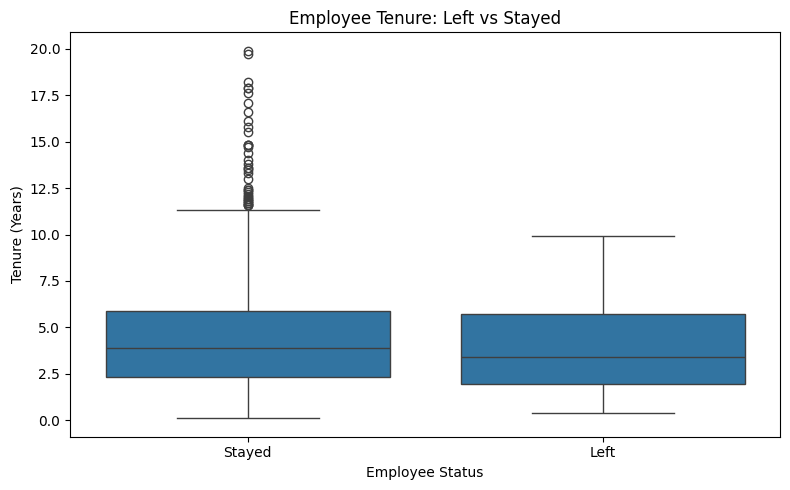

In [24]:
# Compare tenure for employees who left and stayed
tenure_summary = (
    merged.groupby("exit_status")["tenure_years"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(tenure_summary)

# Visualize tenure distribution
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=merged,
    x="exit_status",
    y="tenure_years"
)

plt.title("Employee Tenure: Left vs Stayed")
plt.xlabel("Employee Status")
plt.ylabel("Tenure (Years)")
plt.tight_layout()
plt.show()

,count,mean,median,min,max
exit_status,,,,,
Left,59,17.01,14.3,0.8,45.0
Stayed,941,12.30,10.0,0.3,120.0


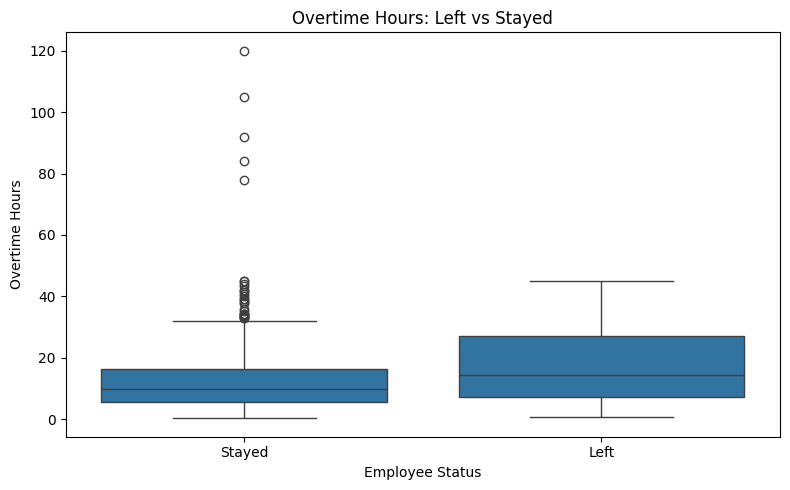

In [25]:
# Compare overtime hours for employees who left and stayed
overtime_summary = (
    merged.groupby("exit_status")["overtime_hours"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(overtime_summary)

# Visualize overtime distribution
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=merged,
    x="exit_status",
    y="overtime_hours"
)

plt.title("Overtime Hours: Left vs Stayed")
plt.xlabel("Employee Status")
plt.ylabel("Overtime Hours")
plt.tight_layout()
plt.show()

,satisfaction_score,work_life_balance_score,manager_support_score
exit_status,,,
Left,3.01,3.04,3.45
Stayed,3.35,3.24,3.42


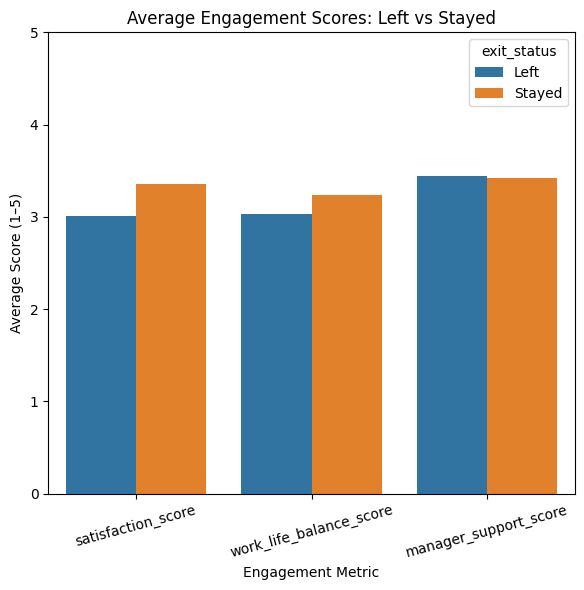

In [26]:
# Compare engagement scores by employee status
engagement_cols = [
    "satisfaction_score",
    "work_life_balance_score",
    "manager_support_score"
]

engagement_summary = (
    merged.groupby("exit_status")[engagement_cols]
    .mean()
    .round(2)
)

display(engagement_summary)

# Visualize the average scores
engagement_plot = (
    merged.groupby("exit_status")[engagement_cols]
    .mean()
    .reset_index()
    .melt(
        id_vars="exit_status",
        var_name="Engagement Metric",
        value_name="Average Score"
    )
)

plt.figure(figsize=(6, 6))
sns.barplot(
    data=engagement_plot,
    x="Engagement Metric",
    y="Average Score",
    hue="exit_status"
)

plt.title("Average Engagement Scores: Left vs Stayed")
plt.xlabel("Engagement Metric")
plt.ylabel("Average Score (1–5)")
plt.ylim(0, 5)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

,promotion_status,total_employees,employees_left,attrition_rate_pct
0,No Recorded Promotions,511,30,5.87
1,Promoted,489,29,5.93


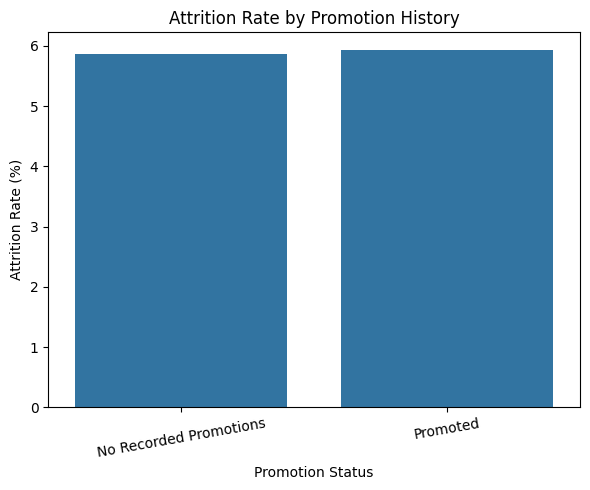

In [27]:
# Create promotion categories using promotion_count
merged["promotion_status"] = pd.NA

merged.loc[
    merged["promotion_count"] > 0, "promotion_status"
] = "Promoted"

merged.loc[
    merged["promotion_count"] == 0, "promotion_status"
] = "No Recorded Promotions"

merged.loc[
    merged["promotion_count"].isna(), "promotion_status"
] = "Unknown"

# Calculate attrition rates
promotion_attrition = (
    merged.groupby("promotion_status", dropna=False)
    .agg(
        total_employees=("employee_id", "nunique"),
        employees_left=("exit_status", lambda x: (x == "Left").sum())
    )
    .reset_index()
)

promotion_attrition["attrition_rate_pct"] = (
    promotion_attrition["employees_left"]
    / promotion_attrition["total_employees"] * 100
).round(2)

display(promotion_attrition)

# Visualize attrition rates
plt.figure(figsize=(6, 5))
sns.barplot(
    data=promotion_attrition,
    x="promotion_status",
    y="attrition_rate_pct"
)

plt.title("Attrition Rate by Promotion History")
plt.xlabel("Promotion Status")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

,role,total_employees,employees_left,attrition_rate_pct
27,Team Lead,76,7,9.21
13,QA Engineer,57,5,8.77
3,Data Analyst,69,6,8.70
25,Support Team Lead,72,6,8.33
21,Senior Software Engineer,68,5,7.35
19,Sales Executive,72,5,6.94
20,Sales Manager,46,3,6.52
6,Financial Analyst,31,2,6.45
11,Operations Associate,71,4,5.63
1,Account Manager,55,3,5.45


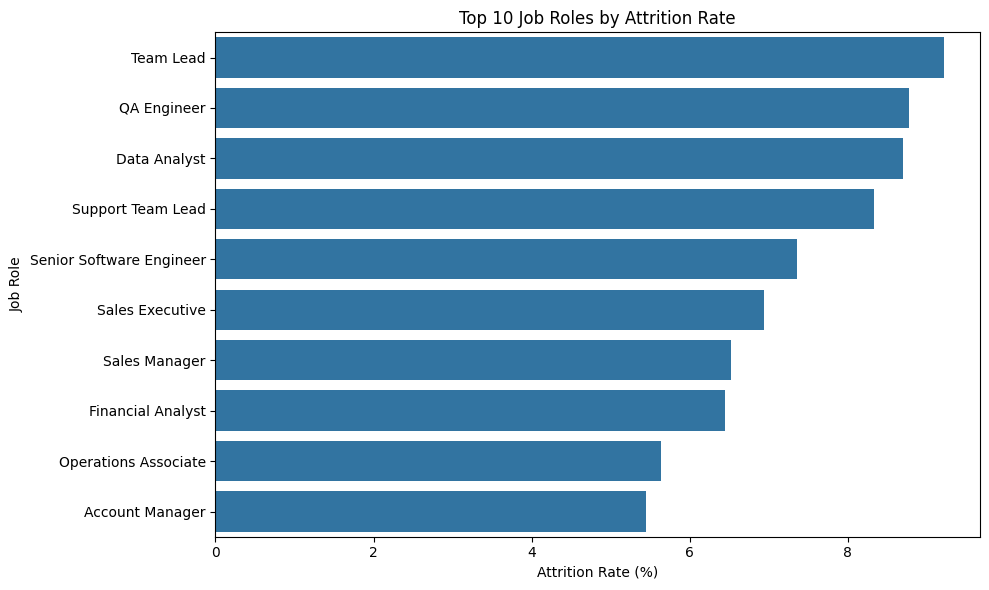

In [28]:
# Calculate attrition by job role
role_attrition = (
    merged.groupby("role")
    .agg(
        total_employees=("employee_id", "nunique"),
        employees_left=("exit_status", lambda x: (x == "Left").sum())
    )
    .reset_index()
)

role_attrition["attrition_rate_pct"] = (
    role_attrition["employees_left"]
    / role_attrition["total_employees"] * 100
).round(2)

# Avoid drawing conclusions from roles with very few employees
role_attrition = role_attrition[
    role_attrition["total_employees"] >= 10
].sort_values("attrition_rate_pct", ascending=False)

display(role_attrition)

# Plot the 10 roles with the highest attrition rates
top_roles = role_attrition.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_roles,
    x="attrition_rate_pct",
    y="role"
)

plt.title("Top 10 Job Roles by Attrition Rate")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

In [29]:
import numpy as np
import pandas as pd

# 1. Group employees by tenure
merged["tenure_group"] = pd.cut(
    merged["tenure_years"],
    bins=[-np.inf, 1, 3, 5, np.inf],
    labels=["0–1 years", "1–3 years", "3–5 years", "5+ years"],
    right=True
)

# 2. Create overtime categories
merged["overtime_category"] = pd.cut(
    merged["overtime_hours"],
    bins=[-np.inf, 10, 20, 60, np.inf],
    labels=["Low", "Moderate", "High", "Extreme"],
    right=True
)

# 3. Calculate average engagement score
engagement_cols = [
    "satisfaction_score",
    "work_life_balance_score",
    "manager_support_score"
]

merged["average_engagement_score"] = (
    merged[engagement_cols].mean(axis=1)
)

# 4. Calculate absence per recorded attendance month
merged["absence_per_month"] = (
    merged["absence_days"]
    / merged["attendance_months"].replace(0, np.nan)
)

# 5. Create a binary attrition target
merged["attrition"] = merged["exit_status"].map({
    "Stayed": 0,
    "Left": 1
})

# Display the new features
new_features = [
    "employee_id",
    "tenure_group",
    "overtime_category",
    "average_engagement_score",
    "absence_per_month",
    "attrition"
]

display(merged[new_features].head(10))

print("New feature columns created successfully.")

,employee_id,tenure_group,overtime_category,average_engagement_score,absence_per_month,attrition
0,EMP0001,1–3 years,Moderate,3.133333,0.250000,0
1,EMP0002,1–3 years,High,3.700000,0.083333,0
2,EMP0003,1–3 years,Low,3.133333,0.083333,0
3,EMP0004,1–3 years,Low,3.300000,0.250000,0
4,EMP0005,3–5 years,High,3.466667,0.666667,0
5,EMP0006,5+ years,High,3.133333,0.166667,0
6,EMP0007,3–5 years,Moderate,3.366667,0.083333,0
7,EMP0008,3–5 years,Low,3.333333,0.500000,0
8,EMP0009,5+ years,Low,3.366667,0.250000,0
9,EMP0010,0–1 years,Moderate,2.700000,0.250000,0


New feature columns created successfully.


In [30]:
# Select useful features for analysis
categorical_cols = [
    "department",
    "role",
    "grade",
    "education_level",
    "work_location",
    "salary_band",
    "survey_participation",
    "promotion_status",
    "tenure_group",
    "overtime_category"
]

# Keep only columns that exist in the dataset
categorical_cols = [
    col for col in categorical_cols if col in merged.columns
]

# One-hot encode categorical variables
encoded_data = pd.get_dummies(
    merged,
    columns=categorical_cols,
    dtype=int
)

print("Original dataset shape:", merged.shape)
print("Encoded dataset shape:", encoded_data.shape)

print("\nEncoded column sample:")
print(encoded_data.columns.tolist()[:30])

display(encoded_data.head())

Original dataset shape: (1000, 38)
Encoded dataset shape: (1000, 93)

Encoded column sample:
['employee_id', 'tenure_years', 'age', 'absence_days', 'overtime_hours', 'leave_days', 'late_arrivals', 'attendance_months', 'overtime_outlier_flag', 'monthly_salary', 'increment_pct', 'benefits_score', 'last_increment_years', 'compensation_issue_flag', 'satisfaction_score', 'work_life_balance_score', 'manager_support_score', 'missing_survey_score_flag', 'promotion_count', 'last_promotion_years', 'transfer_count', 'exit_status', 'exit_date', 'promotion_history_missing', 'movement_issue_flag', 'average_engagement_score', 'absence_per_month', 'attrition', 'department_Customer Support', 'department_Engineering']


,employee_id,tenure_years,age,absence_days,overtime_hours,leave_days,late_arrivals,attendance_months,overtime_outlier_flag,monthly_salary,...,promotion_status_No Recorded Promotions,promotion_status_Promoted,tenure_group_0–1 years,tenure_group_1–3 years,tenure_group_3–5 years,tenure_group_5+ years,overtime_category_Low,overtime_category_Moderate,overtime_category_High,overtime_category_Extreme
0,EMP0001,1.5,24,3,11.2,7,2,12,0,56600,...,0,1,0,1,0,0,0,1,0,0
1,EMP0002,1.4,24,1,23.8,5,2,12,0,75600,...,0,1,0,1,0,0,0,0,1,0
2,EMP0003,1.3,23,1,7.1,4,0,12,0,97500,...,0,1,0,1,0,0,1,0,0,0
3,EMP0004,2.3,30,3,3.4,5,1,12,0,37000,...,0,1,0,1,0,0,1,0,0,0
4,EMP0005,4.7,25,8,22.5,6,4,12,0,36800,...,1,0,0,0,1,0,0,0,1,0


Correlation of numeric features with attrition:


,correlation_with_attrition
overtime_hours,0.104209
satisfaction_score,-0.096325
average_engagement_score,-0.084597
increment_pct,-0.076623
benefits_score,-0.069715
last_promotion_years,-0.056455
work_life_balance_score,-0.054208
tenure_years,-0.046653
leave_days,0.042573
promotion_count,-0.035510


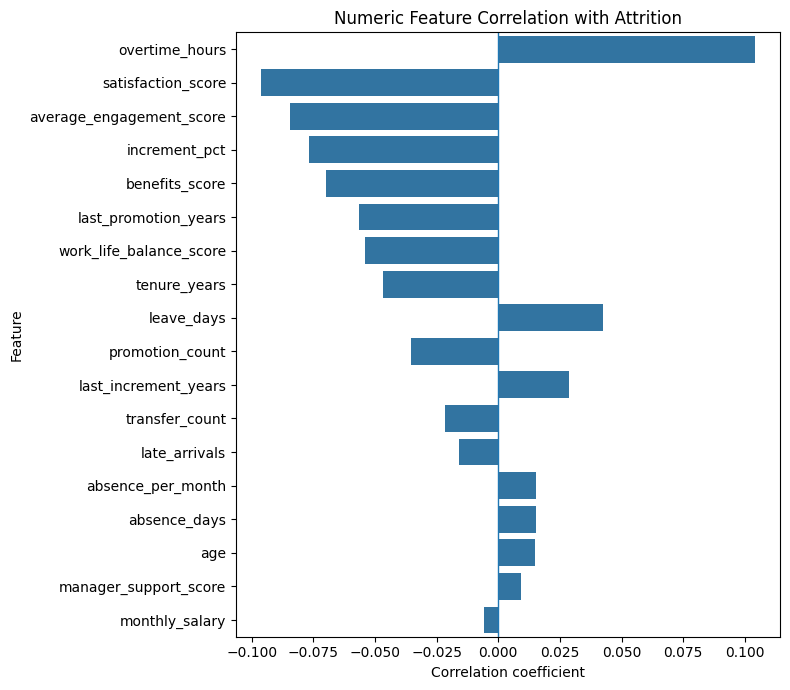

In [31]:
# Select numeric columns for correlation analysis
numeric_features = [
    "tenure_years",
    "age",
    "absence_days",
    "overtime_hours",
    "leave_days",
    "late_arrivals",
    "monthly_salary",
    "increment_pct",
    "benefits_score",
    "last_increment_years",
    "satisfaction_score",
    "work_life_balance_score",
    "manager_support_score",
    "promotion_count",
    "last_promotion_years",
    "transfer_count",
    "average_engagement_score",
    "absence_per_month",
    "attrition"
]

# Keep only columns available in merged
numeric_features = [
    col for col in numeric_features if col in merged.columns
]

# Calculate correlations
correlation_matrix = merged[numeric_features].corr(numeric_only=True)

# Show correlations with attrition
attrition_corr = (
    correlation_matrix["attrition"]
    .drop("attrition")
    .sort_values(key=abs, ascending=False)
)

print("Correlation of numeric features with attrition:")
display(attrition_corr.to_frame(name="correlation_with_attrition"))

# Plot the correlations
plt.figure(figsize=(8, 7))
sns.barplot(
    x=attrition_corr.values,
    y=attrition_corr.index
)
plt.axvline(0, linewidth=1)
plt.title("Numeric Feature Correlation with Attrition")
plt.xlabel("Correlation coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [32]:
from pathlib import Path
import pandas as pd
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED_DIR = Path("/content/processed")
EDA_DIR = PROCESSED_DIR / "eda_evidence"
EDA_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the merged dataset with engineered features
merged.to_csv(
    PROCESSED_DIR / "employee_attrition_final.csv",
    index=False
)

# 2. Save the correlation table
attrition_corr.to_csv(
    EDA_DIR / "attrition_feature_correlations.csv",
    header=["correlation_with_attrition"]
)

# 3. Save EDA summary tables
department_attrition.to_csv(
    EDA_DIR / "department_attrition.csv", index=False
)
tenure_summary.to_csv(
    EDA_DIR / "tenure_summary.csv"
)
overtime_summary.to_csv(
    EDA_DIR / "overtime_summary.csv"
)
engagement_summary.to_csv(
    EDA_DIR / "engagement_summary.csv"
)
promotion_attrition.to_csv(
    EDA_DIR / "promotion_attrition.csv", index=False
)
role_attrition.to_csv(
    EDA_DIR / "role_attrition.csv", index=False
)

# 4. Save key visualizations
def save_plot(filename):
    plt.tight_layout()
    plt.savefig(EDA_DIR / filename, dpi=300, bbox_inches="tight")
    plt.close()

# Department attrition
plt.figure(figsize=(10, 6))
sns.barplot(
    data=department_attrition,
    x="attrition_rate_pct",
    y="department"
)
plt.title("Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
save_plot("department_attrition.png")

# Tenure by exit status
plt.figure(figsize=(8, 5))
sns.boxplot(data=merged, x="exit_status", y="tenure_years")
plt.title("Tenure by Employee Status")
plt.xlabel("Employee Status")
plt.ylabel("Tenure (Years)")
save_plot("tenure_by_status.png")

# Overtime by exit status
plt.figure(figsize=(8, 5))
sns.boxplot(data=merged, x="exit_status", y="overtime_hours")
plt.title("Overtime by Employee Status")
plt.xlabel("Employee Status")
plt.ylabel("Overtime Hours")
save_plot("overtime_by_status.png")

# Engagement by exit status
plt.figure(figsize=(10, 6))
sns.barplot(
    data=engagement_plot,
    x="Engagement Metric",
    y="Average Score",
    hue="exit_status"
)
plt.title("Engagement Scores by Employee Status")
plt.xlabel("Engagement Metric")
plt.ylabel("Average Score")
plt.xticks(rotation=15)
save_plot("engagement_by_status.png")

# Promotion history and attrition
plt.figure(figsize=(9, 5))
sns.barplot(
    data=promotion_attrition,
    x="promotion_status",
    y="attrition_rate_pct"
)
plt.title("Attrition Rate by Promotion History")
plt.xlabel("Promotion Status")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=10)
save_plot("promotion_attrition.png")

# Job roles with highest attrition
plt.figure(figsize=(10, 6))
sns.barplot(
    data=role_attrition.head(10),
    x="attrition_rate_pct",
    y="role"
)
plt.title("Top Job Roles by Attrition Rate")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
save_plot("role_attrition.png")

# 5. Export all processed evidence to one ZIP
zip_path = "/content/Employee_Attrition_Round2_Evidence.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in PROCESSED_DIR.rglob("*"):
        if file.is_file() and file != Path(zip_path):
            zipf.write(file, file.relative_to(PROCESSED_DIR.parent))

print("Final dataset saved.")
print("EDA tables and charts saved.")
print("Evidence ZIP:", zip_path)

print("\nFinal dataset shape:", merged.shape)
print("Unique employees:", merged["employee_id"].nunique())
print("Duplicate employee IDs:", merged["employee_id"].duplicated().sum())

Final dataset saved.
EDA tables and charts saved.
Evidence ZIP: /content/Employee_Attrition_Round2_Evidence.zip

Final dataset shape: (1000, 38)
Unique employees: 1000
Duplicate employee IDs: 0


In [33]:
from google.colab import files
files.download("/content/Employee_Attrition_Round2_Evidence.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path("/content/processed")

required_files = [
    "employees_cleaned.csv",
    "attendance_cleaned.csv",
    "compensation_cleaned.csv",
    "engagement_cleaned.csv",
    "movement_cleaned.csv",
    "employee_attrition_merged.csv",
    "employee_attrition_final.csv"
]

for filename in required_files:
    path = PROCESSED_DIR / filename

    if path.exists():
        df = pd.read_csv(path)
        duplicate_ids = (
            df["employee_id"].duplicated().sum()
            if "employee_id" in df.columns else "N/A"
        )

        print(f"\n✅ {filename}")
        print("   Shape:", df.shape)
        print("   Duplicate employee IDs:", duplicate_ids)
    else:
        print(f"\n❌ Missing: {filename}")


✅ employees_cleaned.csv
   Shape: (1000, 8)
   Duplicate employee IDs: 0

✅ attendance_cleaned.csv
   Shape: (1000, 7)
   Duplicate employee IDs: 0

✅ compensation_cleaned.csv
   Shape: (1000, 7)
   Duplicate employee IDs: 0

✅ engagement_cleaned.csv
   Shape: (1000, 6)
   Duplicate employee IDs: 0

✅ movement_cleaned.csv
   Shape: (1000, 8)
   Duplicate employee IDs: 0

✅ employee_attrition_merged.csv
   Shape: (1000, 32)
   Duplicate employee IDs: 0

✅ employee_attrition_final.csv
   Shape: (1000, 38)
   Duplicate employee IDs: 0


In [35]:
# Check required engineered features
required_columns = [
    "employee_id",
    "tenure_group",
    "overtime_category",
    "average_engagement_score",
    "absence_per_month",
    "attrition"
]

missing_columns = [
    col for col in required_columns
    if col not in merged.columns
]

if missing_columns:
    print("Missing features:", missing_columns)
else:
    print("All required engineered features are present.")

# Check the attrition target
print("\nAttrition target counts:")
print(merged["attrition"].value_counts(dropna=False))

print("\nAttrition target mapping:")
print("0 = Stayed")
print("1 = Left")

# Check missing values in engineered features
print("\nMissing values in engineered features:")
print(merged[required_columns].isnull().sum())

# Preview
display(merged[required_columns].head(10))


All required engineered features are present.

Attrition target counts:
attrition
0    941
1     59
Name: count, dtype: int64

Attrition target mapping:
0 = Stayed
1 = Left

Missing values in engineered features:
employee_id                 0
tenure_group                0
overtime_category           0
average_engagement_score    0
absence_per_month           0
attrition                   0
dtype: int64


,employee_id,tenure_group,overtime_category,average_engagement_score,absence_per_month,attrition
0,EMP0001,1–3 years,Moderate,3.133333,0.250000,0
1,EMP0002,1–3 years,High,3.700000,0.083333,0
2,EMP0003,1–3 years,Low,3.133333,0.083333,0
3,EMP0004,1–3 years,Low,3.300000,0.250000,0
4,EMP0005,3–5 years,High,3.466667,0.666667,0
5,EMP0006,5+ years,High,3.133333,0.166667,0
6,EMP0007,3–5 years,Moderate,3.366667,0.083333,0
7,EMP0008,3–5 years,Low,3.333333,0.500000,0
8,EMP0009,5+ years,Low,3.366667,0.250000,0
9,EMP0010,0–1 years,Moderate,2.700000,0.250000,0


In [36]:
# Rank features by absolute correlation with attrition
feature_ranking = (
    merged.select_dtypes(include="number")
    .corr()["attrition"]
    .drop(labels=["attrition"], errors="ignore")
    .dropna()
    .to_frame(name="correlation_with_attrition")
)

feature_ranking["absolute_correlation"] = (
    feature_ranking["correlation_with_attrition"].abs()
)

feature_ranking = feature_ranking.sort_values(
    "absolute_correlation", ascending=False
)

display(feature_ranking)

# Save the feature ranking
feature_ranking.to_csv(
    "/content/processed/feature_selection_results.csv"
)

print("Feature-selection results saved.")

,correlation_with_attrition,absolute_correlation
overtime_hours,0.104209,0.104209
satisfaction_score,-0.096325,0.096325
average_engagement_score,-0.084597,0.084597
increment_pct,-0.076623,0.076623
benefits_score,-0.069715,0.069715
last_promotion_years,-0.056455,0.056455
work_life_balance_score,-0.054208,0.054208
tenure_years,-0.046653,0.046653
leave_days,0.042573,0.042573
missing_survey_score_flag,-0.042321,0.042321


Feature-selection results saved.


In [37]:
# Final EDA findings summary

print("=" * 55)
print("EMPLOYEE ATTRITION INSIGHT — EDA FINDINGS")
print("=" * 55)

print("\n1. ATTRITION BY DEPARTMENT")
display(department_attrition)

print("\n2. TENURE: LEFT VS STAYED")
display(tenure_summary)

print("\n3. OVERTIME: LEFT VS STAYED")
display(overtime_summary)

print("\n4. ENGAGEMENT SCORES: LEFT VS STAYED")
display(engagement_summary)

print("\n5. PROMOTION HISTORY VS ATTRITION")
display(promotion_attrition)

print("\n6. JOB ROLES WITH HIGHEST ATTRITION")
display(role_attrition.head(10))

print("\n7. FEATURES MOST CORRELATED WITH ATTRITION")
display(feature_ranking.head(10))

EMPLOYEE ATTRITION INSIGHT — EDA FINDINGS

1. ATTRITION BY DEPARTMENT


,department,total_employees,employees_left,attrition_rate_pct
1,Engineering,250,18,7.20
4,Operations,217,14,6.45
5,Sales,175,11,6.29
0,Customer Support,180,10,5.56
2,Finance,100,4,4.00
3,Hr,78,2,2.56



2. TENURE: LEFT VS STAYED


,count,mean,median,min,max
exit_status,,,,,
Left,59,3.89,3.4,0.4,9.9
Stayed,941,4.50,3.9,0.1,19.9



3. OVERTIME: LEFT VS STAYED


...

,promotion_status,total_employees,employees_left,attrition_rate_pct
0,No Recorded Promotions,511,30,5.87
1,Promoted,489,29,5.93



6. JOB ROLES WITH HIGHEST ATTRITION


,role,total_employees,employees_left,attrition_rate_pct
27,Team Lead,76,7,9.21
13,QA Engineer,57,5,8.77
3,Data Analyst,69,6,8.70
25,Support Team Lead,72,6,8.33
21,Senior Software Engineer,68,5,7.35
19,Sales Executive,72,5,6.94
20,Sales Manager,46,3,6.52
6,Financial Analyst,31,2,6.45
11,Operations Associate,71,4,5.63
1,Account Manager,55,3,5.45



7. FEATURES MOST CORRELATED WITH ATTRITION


,correlation_with_attrition,absolute_correlation
overtime_hours,0.104209,0.104209
satisfaction_score,-0.096325,0.096325
average_engagement_score,-0.084597,0.084597
increment_pct,-0.076623,0.076623
benefits_score,-0.069715,0.069715
last_promotion_years,-0.056455,0.056455
work_life_balance_score,-0.054208,0.054208
tenure_years,-0.046653,0.046653
leave_days,0.042573,0.042573
missing_survey_score_flag,-0.042321,0.042321


In [38]:
from google.colab import files

files.download("/content/processed/employee_attrition_final.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>